# Mini-Project 1: Weather Forecast

This notebook geocodes a configured place, requests a daily forecast, and displays a table and chart. Reusable HTTP and parsing code lives in `src/weather_api.py`; offline response samples live in `tests/fixtures/`.

Run the notebook top to bottom. Before sharing or submitting, replace the email placeholder in the configuration cell with your own university email, or set `UNIVERSITY_EMAIL` in the environment. No contact details are invented here.

In [1]:
from pathlib import Path
import json
import os
import sys

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
from src.weather_api import (
    FORECAST_URL, GEOCODING_URL, WeatherAPIError, fetch_metno, geocode,
    get_forecast, parse_forecast, parse_geocoding, parse_metno,
    request_json, urllib_request_json,
)

# User-editable configuration: set your real university email before the MET Norway request.
LOCATION = "Dresden"
DAYS = 7
CANDIDATE_INDEX = 0
UNIVERSITY_EMAIL = os.getenv("UNIVERSITY_EMAIL", "YOUR_UNIVERSITY_EMAIL")
USER_AGENT = f"UCU-OOP-WeatherAssignment/1.0 ({UNIVERSITY_EMAIL})"
REQUEST_HEADERS = {"User-Agent": USER_AGENT}

FIXTURE_DIR = Path("tests") / "fixtures"

def read_fixture(filename):
    """Load a saved JSON response from the offline fixture directory."""
    with (FIXTURE_DIR / filename).open(encoding="utf-8") as fixture_file:
        return json.load(fixture_file)

## Part A: HTTP fundamentals

The first request uses only `urllib.request`, `urllib.parse`, and `json` inside the reusable wrapper. The following `geocode()` call makes the same search with `requests.get(..., params=..., timeout=...)`; it is also the geocoding step used below, avoiding an extra duplicate call. The request helper returns diagnostics so status, content type, and elapsed time can be inspected.

In [2]:
search_params = {"name": LOCATION, "count": 10, "language": "en", "format": "json"}
try:
    urllib_result = urllib_request_json(
        GEOCODING_URL, search_params, headers=REQUEST_HEADERS, timeout=10
    )
    print(f"urllib status: {urllib_result.status_code}")
    print(f"Content-Type: {urllib_result.content_type}")
    print(f"Response time: {urllib_result.elapsed_seconds:.3f} seconds")
except WeatherAPIError as error:
    urllib_result = None
    print(f"urllib request unavailable: {error}")

urllib status: 200
Content-Type: application/json; charset=utf-8
Response time: 1.269 seconds


### `urllib` and `requests`

`urllib` is in the standard library, so it adds no package dependency, but URL encoding, response parsing, status handling, and exception conversion take more explicit code. `urllib.parse.urlencode` makes encoding control visible, and `urllib.request.Request` lets us set headers. `requests` shortens the common path: pass a mapping through `params`, set `timeout`, inspect response metadata, and call `raise_for_status()`. It has a clearer exception hierarchy, but must be installed. Both permit explicit headers and timeouts; neither automatically makes retry policy correct. `src/weather_api.py` puts the shared retry cap, exponential delay, and custom final exception around both approaches.

## Part B: Geocode, forecast, and display

All geocoder candidates are printed with their country and region. Change `CANDIDATE_INDEX` in the configuration cell to select one. If live services are unavailable, malformed, or return no candidates, the notebook reports that fact and uses the saved Dresden sample forecast so the remaining cells still run. That fixture is clearly marked and must not be mistaken for a current forecast.

In [3]:
forecast_is_live = False
try:
    candidates = geocode(LOCATION, headers=REQUEST_HEADERS, timeout=10)
    if not candidates:
        raise WeatherAPIError(f"No location candidates found for {LOCATION!r}")
    for index, candidate in enumerate(candidates):
        region = candidate.get("admin1", "")
        country = candidate.get("country", candidate.get("country_code", ""))
        print(f"{index}: {candidate['name']}, {region}, {country} ({candidate['latitude']:.4f}, {candidate['longitude']:.4f})")
    if not 0 <= CANDIDATE_INDEX < len(candidates):
        raise ValueError("CANDIDATE_INDEX is outside the candidate list")
    location = candidates[CANDIDATE_INDEX]
    forecast_payload = get_forecast(
        location["latitude"], location["longitude"], DAYS,
        headers=REQUEST_HEADERS, timeout=10,
    )
    weather_frame = parse_forecast(forecast_payload)
    forecast_is_live = True
    place_label = f"{location['name']}, {location.get('country', '')}"
except (WeatherAPIError, ValueError) as error:
    print(f"Live forecast unavailable: {error}")
    print("Using the saved fixture below; these values are examples, not live weather.")
    location = read_fixture("geocoding.json")["results"][0]
    weather_frame = parse_forecast(read_fixture("forecast.json"))
    place_label = "Dresden (saved sample fixture)"

print(f"\nSource mode: {'live Open-Meteo' if forecast_is_live else 'offline sample'}")
print(f"Place: {place_label}")
if not weather_frame.empty:
    warmest = weather_frame.loc[weather_frame["Max temp (°C)"].idxmax()]
    wettest = weather_frame.loc[weather_frame["Precipitation (mm)"].idxmax()]
    print(
        f"Summary: high temperature peaks at {warmest['Max temp (°C)']:.1f} °C on "
        f"{warmest['Date'].date()}; greatest daily precipitation is "
        f"{wettest['Precipitation (mm)']:.1f} mm on {wettest['Date'].date()}."
    )

0: Dresden, Saxony, Germany (51.0509, 13.7383)
1: Dresden, Tennessee, United States (36.2914, -88.7081)
2: Dresden, Ohio, United States (40.1215, -82.0107)
3: Dresden, New York, United States (42.6840, -76.9558)
4: Dresden, Kansas, United States (39.6242, -100.4224)
5: Dresden, Georgia, United States (33.3515, -84.9185)
6: Dresden, Missouri, United States (38.7511, -93.3349)
7: Dresden, North Carolina, United States (36.4582, -81.5457)
8: Dresden, Texas, United States (32.0307, -96.6805)
9: Dresden, Iowa, United States (42.9791, -92.3185)

Source mode: live Open-Meteo
Place: Dresden, Germany
Summary: high temperature peaks at 20.3 °C on 2026-10-16; greatest daily precipitation is 1.0 mm on 2026-10-14.


In [4]:
weather_frame

,Date,Min temp (°C),Max temp (°C),Precipitation (mm),Max wind (km/h),Conditions
0,2026-10-13,3.4,16.5,0.0,9.7,Slight rain
1,2026-10-14,9.7,16.6,1.0,14.8,Slight rain
2,2026-10-15,5.2,17.2,0.0,3.9,Fog
3,2026-10-16,4.4,20.3,0.0,8.4,Overcast
4,2026-10-17,9.1,13.2,0.6,13.7,Slight rain
5,2026-10-18,5.8,11.6,0.0,8.2,Overcast
6,2026-10-19,7.0,11.8,0.0,8.2,Fog


KeyError: 'Min temp (Â°C)'

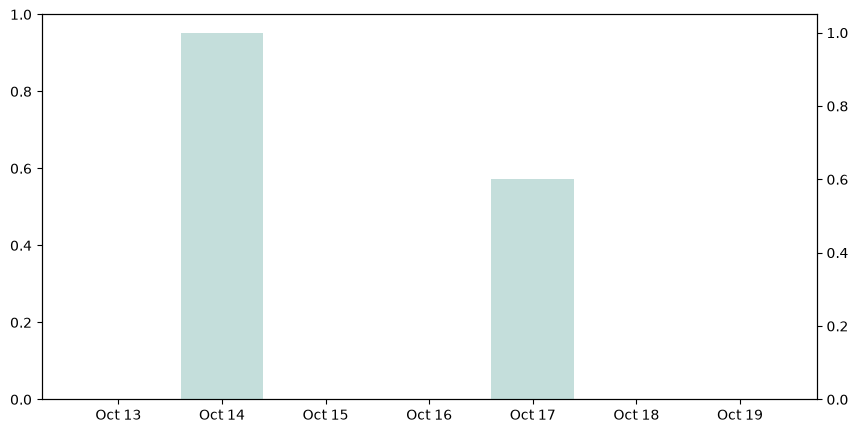

In [5]:
fig, temperature_axis = plt.subplots(figsize=(10, 5))
precipitation_axis = temperature_axis.twinx()
dates = weather_frame["Date"].dt.strftime("%b %d")
precipitation_axis.bar(dates, weather_frame["Precipitation (mm)"], color="#4a9b91", alpha=0.32, label="Precipitation (mm)")
temperature_axis.fill_between(
    range(len(weather_frame)), weather_frame["Min temp (Â°C)"],
    weather_frame["Max temp (Â°C)"], color="#e28a54", alpha=0.28, label="Temperature range"
)
temperature_axis.plot(dates, weather_frame["Min temp (Â°C)"], color="#347d78", marker="o", label="Minimum (Â°C)")
temperature_axis.plot(dates, weather_frame["Max temp (Â°C)"], color="#c4613e", marker="o", label="Maximum (Â°C)")
temperature_axis.set_ylabel("Temperature (Â°C)")
precipitation_axis.set_ylabel("Precipitation (mm)")
temperature_axis.set_title(f"Daily forecast: {place_label}")
temperature_axis.set_xlabel("Local date")
temperature_axis.legend(loc="upper left")
precipitation_axis.legend(loc="upper right")
fig.tight_layout()
plt.show()

**Data source:** [Open-Meteo Geocoding API](https://open-meteo.com/en/docs/geocoding-api) and [Open-Meteo Forecast API](https://open-meteo.com/en/docs). Location results use GeoNames; weather codes follow the WMO interpretation mapping in the forecast documentation. Forecast and geocoding API data: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Open-Meteo attribution is required.

## Part C: Robustness and second source

Requests have finite timeouts, HTTP status checks, retry limits, and exponential backoff. Connection/timeouts and server errors are retried; client errors are not. Invalid coordinates are rejected before a request. Each deliberately broken case below is caught and reported so it does not stop the notebook.

In [ ]:
print("Invalid city demonstration:")
try:
    invalid_candidates = geocode("zzzxq-no-such-place-74291", headers=REQUEST_HEADERS, timeout=5)
    print("No geocoder matches." if not invalid_candidates else f"Unexpected candidates: {invalid_candidates}")
except WeatherAPIError as error:
    print(f"Geocoder unavailable; empty-result handling is covered by fixtures: {error}")

print("Invalid latitude demonstration:")
try:
    get_forecast(95.0, 13.7, DAYS, headers=REQUEST_HEADERS)
except ValueError as error:
    print(f"Rejected before network access: {error}")

In [ ]:
import requests

class OfflineSession:
    """A tiny fake session that simulates a disconnected network."""
    def get(self, *args, **kwargs):
        raise requests.ConnectionError("simulated network is offline")

try:
    request_json(
        GEOCODING_URL, search_params, session=OfflineSession(),
        max_retries=1, sleep_fn=lambda delay: None,
    )
except WeatherAPIError as error:
    print(f"Offline simulation produced the expected custom error: {error}")

In [ ]:
try:
    tiny_result = request_json(
        GEOCODING_URL, search_params, headers=REQUEST_HEADERS,
        timeout=1e-6, max_retries=0,
    )
    print(f"The tiny-timeout request happened to finish: HTTP {tiny_result.status_code}")
except (WeatherAPIError, ValueError) as error:
    print(f"Tiny timeout handled without stopping the notebook: {error}")

### MET Norway Locationforecast 2.0

MET Norway's compact response is an independent forecast format with time-series values rather than Open-Meteo's daily aggregates. Its policy requires a descriptive User-Agent that includes contact information; the notebook skips the live call until the real university email has been entered. Coordinates are rounded to four decimal places and only one request is made.

In [ ]:
if UNIVERSITY_EMAIL == "YOUR_UNIVERSITY_EMAIL":
    print("MET Norway request skipped: replace the email placeholder in the configuration cell first.")
else:
    try:
        metno_payload = fetch_metno(
            location["latitude"], location["longitude"],
            user_agent=USER_AGENT, timeout=10,
        )
        metno_frame = pd.DataFrame(parse_metno(metno_payload))
        print("Source: MET Norway Locationforecast 2.0; attribution: MET Norway, CC BY 4.0.")
        print(metno_frame.head().to_string(index=False))
    except (WeatherAPIError, ValueError, NameError) as error:
        print(f"MET Norway forecast unavailable: {error}")

### Offline parser checks

These assertion-based checks use only saved JSON fixtures, so their results do not depend on either weather provider being reachable. The same behaviors also have eight `unittest` checks in `tests/`.

In [ ]:
geo_sample = read_fixture("geocoding.json")
empty_geo_sample = read_fixture("geocoding_empty.json")
forecast_sample = read_fixture("forecast.json")
metno_sample = read_fixture("metno.json")
sample_frame = parse_forecast(forecast_sample)
sample_metno = parse_metno(metno_sample)
assert parse_geocoding(geo_sample)[0]["name"] == "Dresden"
assert parse_geocoding(empty_geo_sample) == []
assert len(sample_frame) == 3
assert sample_frame.loc[0, "Conditions"] == "Mainly clear"
assert sample_frame.loc[1, "Conditions"] == "Slight rain"
assert sample_frame.loc[2, "Max wind (km/h)"] == 22.1
assert sample_metno[0]["Temperature (Â°C)"] == 11.3
assert sample_metno[0]["Symbol"] == "partlycloudy_day"
print("8 offline parsing assertions passed.")

# Project Report

## Purpose and data flow

This project turns a human-readable place into a forecast without an API wrapper library. The user sets the place, number of days, candidate index, and contact email in one configuration cell. The first HTTP comparison calls Open-Meteo Geocoding with `urllib`; the reusable `geocode()` function repeats that search using `requests` and its `params` mapping. The candidates include names, administrative regions, countries, coordinates, and, when supplied, time zones. Printing every candidate makes a shared name visible instead of silently taking the first result. The configured index is the explicit selection.

The selected latitude and longitude are passed to Open-Meteo Forecast. The request asks for daily minimum and maximum two-metre air temperature, total precipitation, maximum ten-metre wind speed, and the daily WMO weather code. The timezone value is `auto`, which lets Open-Meteo resolve the time zone from the coordinates and define the daily boundaries locally. The returned JSON is checked for required arrays and equal lengths before it becomes a pandas DataFrame. Column names include units, and codes are mapped to the descriptions in the provider documentation. The notebook then produces a short summary, a formatted table, and a chart combining a shaded minimum-to-maximum temperature range with precipitation on a second axis.

```mermaid
flowchart LR
    A[User configuration: place, days, email] --> B[Geocoding API]
    B --> C[Candidate list and configured selection]
    C --> D[Latitude, longitude, local timezone]
    D --> E[Open-Meteo daily forecast JSON]
    E --> F[Validate and parse into pandas]
    F --> G[Summary, table, temperature and rain chart]
    H[Saved JSON fixtures] --> F
```

The fixtures support offline checks and a clearly labeled fallback when a live endpoint is down. They are examples, not stale data disguised as current forecasts. The fixture values exercise parsing for three sample dates: two weather conditions are decoded as mainly clear and slight rain, and the final sample day has a 22.1 km/h maximum wind. These values describe only the checked-in test record. Live forecast values change on every run, so findings must be read alongside the mode label and retrieval time rather than treated as a stable research dataset.

## HTTP choices and reliability

`urllib` is part of Python and is suitable where minimizing dependencies matters. It makes URL construction and response decoding explicit: the query is assembled with `urllib.parse.urlencode`, a `Request` carries headers, and the response bytes are decoded as JSON. In contrast, `requests` accepts the query mapping directly via `params`, supplies a convenient response object, and offers a clear `raise_for_status()` check. That convenience does not remove the need to choose timeouts, interpret status codes, validate JSON shape, or decide which failures are retryable. The response diagnostics cell records an HTTP status, Content-Type, and elapsed time when the service can be reached. The runtime values are observations from that execution, not universal API performance claims.

Both transports are wrapped in functions with finite timeouts and a maximum of two retries after the first attempt. A delay of one-half second doubles after each retry. Network connection failures and timeouts are transient candidates; HTTP 5xx responses are also retried. HTTP 4xx responses normally describe a bad query or rejected request, so repeating them would waste traffic and will not fix the input. A final failure becomes `WeatherAPIError`, making it possible for notebook cells to explain the problem while continuing to offline examples. Successful HTTP status alone is insufficient: non-object JSON, invalid JSON, absent fields, and unequal daily arrays are checked separately. Coordinates outside WGS84 bounds and forecast lengths outside the supported range are rejected before networking. MET Norway coordinates are rounded to four decimals in accordance with its service terms.

Forecast services are external dependencies. They can be slow, rate-limited, unavailable, change response data, or return a valid response that lacks an optional field. Retries can soften a short outage but cannot provide an uptime guarantee; excessive retry loops would worsen service load, so the cap is deliberately small. The invalid-place example demonstrates a legitimate empty geocoder response, the bad-latitude example proves local validation, the fake session simulates total network loss without making requests, and a one-microsecond timeout probes time-limit handling. The tiny-timeout example is inherently environment-dependent: it may fail, or a nearby cache/network path could respond before the deadline. Either result is reported without making the notebook fail.

The eight offline unit tests and notebook assertions cover normal parsing, missing geocoder results, WMO decoding, misaligned arrays, MET Norway extraction, coordinate validation, and retry caps for connection and server failures. This gives deterministic checks without consuming API quota. The live cells still need a network connection for current data. When live geocoding or forecasting cannot be used, fixture mode keeps later plotting and parsing reproducible and visibly labels the result as sample data. A product would normally cache successful responses and honor provider cache headers; this small coursework notebook avoids repeated requests and makes only the calls needed to demonstrate each part.

## Licensing, attribution, and product implications

Open-Meteo states that API data are offered under Creative Commons Attribution 4.0 International (CC BY 4.0). This license permits sharing and adaptation, including commercial reuse, provided appropriate credit is given, a link to the license is supplied, changes are indicated, and no endorsement is implied. Its licensing page asks applications to place a clear Open-Meteo attribution near displayed data. The geocoding documentation identifies GeoNames as the location-data basis, also under CC BY; products that redistribute location results should preserve relevant attribution. Open-Meteoâ€™s free API terms are narrower than the data license: free service is for non-commercial use, below 10,000 API calls per day, 5,000 per hour, and 600 per minute. Commercial services or higher-volume use must choose an appropriate paid plan. Thus CC BY permission for the data does not itself authorize a commercial product to use the free endpoint. A production team must budget for service access, check current terms and upstream model licenses, show attribution, and revisit terms as providers update them.

MET Norwayâ€™s Locationforecast terms also require attribution under CC BY 4.0, identifying the source and linking the license. Its terms require clients to identify themselves in a descriptive User-Agent and include contact information, avoid unnecessary traffic, use HTTPS, and limit coordinate precision to at most four decimal places. The service advises caching responses and respecting expiry information. The terms describe a public, non-commercially operated service with no delivery guarantee or service-level agreement; they do not offer a paid higher-volume tier. A real product must not assume that public access is a support contract. It should plan for outages and throttling, make its own contact identifier truthful, cache responsibly, and determine whether its operational and commercial use fits the current MET Norway policy. The notebook uses one MET Norway request only when the user has filled in their real email, rounds coordinates, and reports failures without claiming guaranteed availability.

Forecast values are model outputs, not observations or a promise about future conditions. Open-Meteo documents multiple upstream meteorological models; model coverage, interpolation, update timing, and forecast horizons vary. Both providers disclaim uninterrupted service or perfect accuracy. A safety-critical or commercial product should communicate uncertainty, indicate provider and retrieval time, avoid presenting a forecast as an authoritative measurement, and evaluate whether a paid or otherwise supported data arrangement is needed. It should also review the underlying source licenses separately rather than assuming every value from an aggregator shares identical provenance. This coursework report describes the providersâ€™ published terms as consulted on the date shown in the references; terms can change and should be rechecked before deployment.

## Privacy, limitations, and conclusion

A place name is sent to the geocoding provider. After selection, the resulting coordinates are sent to one or more forecast providers. A city-level query is usually not directly identifying, but a precise home, workplace, clinic, or repeated movement pattern can reveal sensitive information. Network requests also expose the clientâ€™s IP address and request metadata to the provider; the User-Agent intentionally discloses a contact email to MET Norway so it can identify and reach the client. Open-Meteoâ€™s published privacy terms state that free-service logs can include IP addresses and coordinates for technical purposes and are deleted after 90 days. MET Norway explains that access logs are stored in its Oslo data center and that API logs can include IP addresses and requested coordinates. Its terms say a developer is responsible for the confidentiality of usersâ€™ personal data and recommend a proxy when anonymity from the provider is needed.

For a real application, minimize location precision to what the feature needs, avoid retaining raw queries longer than necessary, explain which providers receive the request, and do not put personal data in URLs or logs. A backend proxy can avoid exposing each end userâ€™s IP address and centralize caching, contact headers, quotas, and access controls, but the proxy operator then takes on security and privacy responsibilities. Consent or another lawful basis may be needed depending on the jurisdiction and whether location is associated with an identifiable person. A student notebook is simpler: it queries only the configured place and makes no continuous tracking requests. Users should still avoid entering a sensitive exact address when a city-level forecast is sufficient.

The implementation demonstrates the end-to-end flow and keeps parsing independent from the network. It does not claim forecasts are exact, does not hide fixture data as a live result, and makes error behavior observable. One limitation is that the selected geocoder candidate index is configured manually rather than through an interactive prompt; this keeps Restart & Run All deterministic while still presenting candidate choices for the user to select in the configuration cell. Another is that daily aggregations do not expose intraday timing, and the MET Norway series is not normalized into the same daily bins, so the two providers should not be compared as if they used identical aggregation rules.

For the assignment, the result is a reproducible demonstration rather than a forecast service: dependencies are declared, parsing fixtures are saved, tests are offline, and every network path has a timeout and bounded retry behavior. Before using the notebook in a public product, confirm the current provider terms, fill in real contact details, implement caching and service monitoring, decide how failures and stale data are communicated, and seek legal/privacy review for location handling.

## References

- [Open-Meteo Geocoding documentation](https://open-meteo.com/en/docs/geocoding-api)
- [Open-Meteo Forecast documentation and WMO weather-code mapping](https://open-meteo.com/en/docs)
- [Open-Meteo license](https://open-meteo.com/en/licence) and [terms and privacy](https://open-meteo.com/en/terms)
- [MET Norway Locationforecast 2.0 documentation](https://api.met.no/weatherapi/locationforecast/2.0/documentation)
- [MET Norway Terms of Service](https://api.met.no/doc/TermsOfService) and [FAQ](https://api.met.no/doc/FAQ)
- [Creative Commons Attribution 4.0 International](https://creativecommons.org/licenses/by/4.0/)

Documentation checked: 10 October 2026. Verify current terms before any deployment.